<a href="https://colab.research.google.com/github/rodrigoesborges/conju-python/blob/main/GRUPO%204%20tabelas%20(politica%20monet%C3%A1ria)%20meta%20de%20infla%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
!pip install python-bcb

In [47]:
from bcb import sgs
metadeinflacao = sgs.get([13521,189]).fillna(method='ffill').fillna(method='bfill')
print(metadeinflacao)
print(igp)

SGSError: Download error: code = 189

In [ ]:
import pandas as pd
metadeinflacao=pd.DataFrame(metadeinflacao)
print(metadeinflacao)

            13521    189
Date                    
1989-06-01    8.0  19.68
1989-07-01    8.0  35.90
1989-08-01    8.0  36.92
1989-09-01    8.0  39.92
1989-10-01    8.0  40.64
...           ...    ...
2026-05-01    3.0   0.84
2026-06-01    3.0  -0.50
2026-07-01    3.0  -1.16
2026-08-01    3.0  -0.22
2026-09-01    3.0   1.57

[448 rows x 2 columns]


In [ ]:
metadeinflacao.nlargest(3,"13521").sort_values("13521",ascending=False)["13521"]

,13521
Date,
1989-06-01,8.0
1989-07-01,8.0
1989-08-01,8.0


In [30]:
!pip install python-bcb

In [39]:
!pip install ipeadatapy

In [60]:
import ipeadatapy
igp = ipeadatapy.timeseries("IGP12_IGPM12")
igp = igp.rename(columns={"DATE":"periodo","CODE":"indicador","VALUE (-)":"valor"})
print(igp)


               indicador                   RAW DATE  DAY  MONTH  YEAR  \
DATE                                                                    
1989-06-01  IGP12_IGPM12  1989-06-01T00:00:00-03:00    1      6  1989   
1989-07-01  IGP12_IGPM12  1989-07-01T00:00:00-03:00    1      7  1989   
1989-08-01  IGP12_IGPM12  1989-08-01T00:00:00-03:00    1      8  1989   
1989-09-01  IGP12_IGPM12  1989-09-01T00:00:00-03:00    1      9  1989   
1989-10-01  IGP12_IGPM12  1989-10-01T00:00:00-03:00    1     10  1989   
...                  ...                        ...  ...    ...   ...   
2026-06-01  IGP12_IGPM12  2026-06-01T00:00:00-03:00    1      6  2026   
2026-07-01  IGP12_IGPM12  2026-07-01T00:00:00-03:00    1      7  2026   
2026-08-01  IGP12_IGPM12  2026-08-01T00:00:00-03:00    1      8  2026   
2026-09-01  IGP12_IGPM12  2026-09-01T00:00:00-03:00    1      9  2026   
2026-10-01  IGP12_IGPM12  2026-10-01T00:00:00-03:00    1     10  2026   

                  valor  
DATE                    

In [63]:
import time
import pandas as pd
import numpy as np
from bcb import sgs
import ipeadatapy as ipea

# Função auxiliar com retry automático para evitar falhas de conexão na API do BCB
def baixar_sgs_seguro(codigo, nome, inicio='1995-01-01', tentativas=5):
    for i in range(tentativas):
        try:
            df = sgs.get({nome: codigo}, start=inicio)
            return df
        except Exception as e:
            print(f"Oscilação na API do BCB para {nome} ({codigo}). Tentando novamente ({i+1}/{tentativas})...")
            time.sleep(2)
    raise RuntimeError(f"Não foi possível baixar a série {codigo} após {tentativas} tentativas.")

# 0) OBTENÇÃO DOS DADOS VIA APIs (BCB SGS + IPEADATA)
# 0.1) Séries do Banco Central (baixadas separadamente para maior estabilidade)
df_meta = baixar_sgs_seguro(13521, 'Meta de Inflacao', inicio='1995-01-01')
df_igpm = baixar_sgs_seguro(189, 'IGP-M (% mensal)', inicio='1995-01-01')

df_bcb = df_meta.join(df_igpm, how='outer').ffill().bfill()
df_bcb.index.name = 'Date'

# 0.2) Série do Ipeadata (IGP12_IGPM12 = IGP-M Número-Índice)
df_ipea = ipea.timeseries('IGP12_IGPM12')
df_ipea.index = pd.to_datetime(df_ipea.index).to_period('M').to_timestamp()
df_ipea.index.name = 'Date'
df_ipea = df_ipea[['VALUE (-)']].rename(columns={'VALUE (-)': 'IGP-M Indice (Ipeadata)'})

# Junta BCB + Ipeadata
df_junto = df_bcb.join(df_ipea, how='inner').reset_index()

# 1) OBTENÇÃO DA TABELA BASE EM FORMATO LONGO
df_junto['periodo'] = df_junto['Date'].dt.strftime('%Y%m%d').astype(int)

tabela_base = (
    df_junto.melt(
        id_vars=['periodo', 'Date'],
        value_vars=['Meta de Inflacao', 'IGP-M (% mensal)', 'IGP-M Indice (Ipeadata)'],
        var_name='indicador',
        value_name='valor'
    )
    .sort_values(['indicador', 'periodo'])
    .reset_index(drop=True)
)

print("--- 1) TABELA BASE (Formato Longo com BCB + Ipeadata) ---")
display(tabela_base[['periodo', 'indicador', 'valor']].tail(9))

--- 1) TABELA BASE (Formato Longo com BCB + Ipeadata) ---


,periodo,indicador,valor
1137,20260201,Meta de Inflacao,3.0
1138,20260301,Meta de Inflacao,3.0
1139,20260401,Meta de Inflacao,3.0
1140,20260501,Meta de Inflacao,3.0
1141,20260601,Meta de Inflacao,3.0
1142,20260701,Meta de Inflacao,3.0
1143,20260801,Meta de Inflacao,3.0
1144,20260901,Meta de Inflacao,3.0
1145,20261001,Meta de Inflacao,3.0


In [25]:
metadeinflacao.nlargest(3,"189").sort_values("189",ascending=False)["189"]

,189
Date,
1990-03-01,83.95
1990-02-01,81.29
1990-01-01,61.46


In [37]:
import pandas as pd
import numpy as np
from bcb import sgs

# 0) OBTENÇÃO DOS DADOS VIA API DO BCB (Garante que 'metadeinflacao' exista na memória)
metadeinflacao = sgs.get([13521, 189]).ffill().bfill()

# 1) OBTENÇÃO DA TABELA BASE EM FORMATO LONGO
df_base = metadeinflacao.copy()

# Renomeia os códigos '13521' e '189' para nomes legíveis
df_base = df_base.rename(columns={
    '13521': 'Meta de Inflacao',
    '189': 'IGP-M'
})

# Transforma o índice 'Date' em coluna e cria o 'periodo' no formato YYYYMMDD
df_base = df_base.reset_index()
df_base['periodo'] = df_base['Date'].dt.strftime('%Y%m%d').astype(int)

# Converte de largo (wide) para longo (long)
tabela_base = (
    df_base.melt(
        id_vars=['periodo', 'Date'],
        value_vars=['Meta de Inflacao', 'IGP-M'],
        var_name='indicador',
        value_name='valor'
    )
    .sort_values(['indicador', 'periodo'])
    .reset_index(drop=True)
)

print("--- TABELA BASE (Formato Longo) ---")
display(tabela_base[['periodo', 'indicador', 'valor']].tail(6))

--- TABELA BASE (Formato Longo) ---


,periodo,indicador,valor
892,20260501,Meta de Inflacao,3.0
893,20260601,Meta de Inflacao,3.0
894,20260701,Meta de Inflacao,3.0
895,20260801,Meta de Inflacao,3.0
896,20260901,Meta de Inflacao,3.0
897,20261001,Meta de Inflacao,3.0


In [36]:
# 2) FUNÇÕES PARA ACUMULADO NO ANO E ACUMULADO EM 12 MESES
# Configuração de cada série:
# - 'IGP-M': variação % mensal -> tipo 'taxa' (juros compostos), frequência 'mensal'
# - 'Meta de Inflacao': meta anual vigente -> tipo 'estoque' (mantém o nível), frequência 'mensal'
config_series = {
    'IGP-M': {'tipo': 'taxa', 'freq': 'mensal'},
    'Meta de Inflacao': {'tipo': 'estoque', 'freq': 'mensal'}
}

def acumulado_ano(df, config):
    df_calc = df.sort_values(['indicador', 'Date']).copy()
    df_calc['ano'] = df_calc['Date'].dt.year
    resultados = []

    for ind, grupo in df_calc.groupby('indicador', sort=False):
        tipo = config[ind]['tipo']
        g = grupo.copy()

        if tipo == 'taxa':
            # Juros compostos dentro do mesmo ano
            g['fator'] = 1 + (g['valor'] / 100.0)
            g['valor_acum'] = (g.groupby('ano')['fator'].cumprod() - 1) * 100.0
        elif tipo == 'fluxo':
            # Soma simples dentro do mesmo ano
            g['valor_acum'] = g.groupby('ano')['valor'].cumsum()
        elif tipo == 'estoque':
            # Variável de estoque: mantém o próprio nível do período
            g['valor_acum'] = g['valor']

        resultados.append(g[['periodo', 'Date', 'indicador', 'valor_acum']].rename(columns={'valor_acum': 'valor'}))

    return pd.concat(resultados, ignore_index=True)


def acumulado_12m(df, config):
    df_calc = df.sort_values(['indicador', 'Date']).copy()
    resultados = []

    for ind, grupo in df_calc.groupby('indicador', sort=False):
        tipo = config[ind]['tipo']
        freq = config[ind]['freq']
        janela = 12 if freq == 'mensal' else 4
        g = grupo.copy()

        if tipo == 'taxa':
            # Produto móvel de 12 meses: prod(1 + r/100) - 1
            g['fator'] = 1 + (g['valor'] / 100.0)
            g['valor_12m'] = (
                g['fator']
                .rolling(window=janela, min_periods=janela)
                .apply(np.prod, raw=True) - 1
            ) * 100.0
        elif tipo == 'fluxo':
            # Soma móvel de 12 meses
            g['valor_12m'] = g['valor'].rolling(window=janela, min_periods=janela).sum()
        elif tipo == 'estoque':
            # Variável de estoque: mantém o nível vigente
            g['valor_12m'] = g['valor']

        resultados.append(g[['periodo', 'Date', 'indicador', 'valor_12m']].rename(columns={'valor_12m': 'valor'}))

    return pd.concat(resultados, ignore_index=True)

In [44]:
config_igp = {
    'VALUE (-)': {'tipo': 'estoque', 'freq': 'mensal'}}
tabela_intermediaria_1igp = acumulado_ano(igp, config_igp)


KeyError: 'indicador'

In [33]:
# 3) APLICAÇÃO DAS FUNÇÕES -> TABELAS INTERMEDIÁRIAS

# --- TABELA INTERMEDIÁRIA 1 (Acumulado no ano) ---
tabela_intermediaria_1 = acumulado_ano(tabela_base, config_series)
print("--- TABELA INTERMEDIÁRIA 1 (Acumulado no Ano) ---")
display(tabela_intermediaria_1[['periodo', 'indicador', 'valor']].tail(6))


# --- TABELA INTERMEDIÁRIA 2 (Acumulado em 12 meses) ---
tabela_intermediaria_2 = (
    acumulado_12m(tabela_base, config_series)
    .dropna(subset=['valor'])
    .reset_index(drop=True)
)
print("\n--- TABELA INTERMEDIÁRIA 2 (Acumulado em 12 Meses) ---")
display(tabela_intermediaria_2[['periodo', 'indicador', 'valor']].tail(6))


# --- TABELA INTERMEDIÁRIA 3 (Var. do Acumulado no ano vs 12 meses antes) ---
t3 = tabela_intermediaria_1[['periodo', 'indicador', 'valor']].copy()
t3['periodo_anterior'] = t3['periodo'] - 10000  # Subtrai 1 ano (ex: 20260901 -> 20250901)

tabela_intermediaria_3 = pd.merge(
    t3,
    t3[['periodo', 'indicador', 'valor']],
    left_on=['indicador', 'periodo_anterior'],
    right_on=['indicador', 'periodo'],
    suffixes=('', '.y')
)

tabela_intermediaria_3['var_acum_ano'] = (tabela_intermediaria_3['valor'] / tabela_intermediaria_3['valor.y']) - 1
tabela_intermediaria_3 = tabela_intermediaria_3[['periodo', 'periodo_anterior', 'indicador', 'valor', 'valor.y', 'var_acum_ano']]

print("\n--- TABELA INTERMEDIÁRIA 3 (Var. Acum. Ano vs 12m antes) ---")
display(tabela_intermediaria_3.tail(6))


# --- TABELA INTERMEDIÁRIA 4 (Var. de 12 meses vs 12 meses anteriores) ---
t4 = tabela_intermediaria_2[['periodo', 'indicador', 'valor']].copy()
t4['periodo_anterior'] = t4['periodo'] - 10000

tabela_intermediaria_4 = pd.merge(
    t4,
    t4[['periodo', 'indicador', 'valor']],
    left_on=['indicador', 'periodo_anterior'],
    right_on=['indicador', 'periodo'],
    suffixes=('', '.y')
)

tabela_intermediaria_4['var_12m'] = (tabela_intermediaria_4['valor'] / tabela_intermediaria_4['valor.y']) - 1
tabela_intermediaria_4 = tabela_intermediaria_4[['periodo', 'periodo_anterior', 'indicador', 'valor', 'valor.y', 'var_12m']]

print("\n--- TABELA INTERMEDIÁRIA 4 (Var. 12m vs 12m anteriores) ---")
display(tabela_intermediaria_4.tail(6))

--- TABELA INTERMEDIÁRIA 1 (Acumulado no Ano) ---


,periodo,indicador,valor
892,20260501,Meta de Inflacao,3.0
893,20260601,Meta de Inflacao,3.0
894,20260701,Meta de Inflacao,3.0
895,20260801,Meta de Inflacao,3.0
896,20260901,Meta de Inflacao,3.0
897,20261001,Meta de Inflacao,3.0



--- TABELA INTERMEDIÁRIA 2 (Acumulado em 12 Meses) ---


,periodo,indicador,valor
881,20260501,Meta de Inflacao,3.0
882,20260601,Meta de Inflacao,3.0
883,20260701,Meta de Inflacao,3.0
884,20260801,Meta de Inflacao,3.0
885,20260901,Meta de Inflacao,3.0
886,20261001,Meta de Inflacao,3.0



--- TABELA INTERMEDIÁRIA 3 (Var. Acum. Ano vs 12m antes) ---


,periodo,periodo_anterior,indicador,valor,valor.y,var_acum_ano
868,20260501,20250501,Meta de Inflacao,3.0,3.0,0.0
869,20260601,20250601,Meta de Inflacao,3.0,3.0,0.0
870,20260701,20250701,Meta de Inflacao,3.0,3.0,0.0
871,20260801,20250801,Meta de Inflacao,3.0,3.0,0.0
872,20260901,20250901,Meta de Inflacao,3.0,3.0,0.0
873,20261001,20251001,Meta de Inflacao,3.0,3.0,0.0



--- TABELA INTERMEDIÁRIA 4 (Var. 12m vs 12m anteriores) ---


,periodo,periodo_anterior,indicador,valor,valor.y,var_12m
857,20260501,20250501,Meta de Inflacao,3.0,3.0,0.0
858,20260601,20250601,Meta de Inflacao,3.0,3.0,0.0
859,20260701,20250701,Meta de Inflacao,3.0,3.0,0.0
860,20260801,20250801,Meta de Inflacao,3.0,3.0,0.0
861,20260901,20250901,Meta de Inflacao,3.0,3.0,0.0
862,20261001,20251001,Meta de Inflacao,3.0,3.0,0.0


In [34]:
# 4) JUNÇÃO FINAL
ultimos_3_periodos = sorted(tabela_base['periodo'].unique())[-3:]
ultimo_periodo = ultimos_3_periodos[-1]

# Da Tabela Base: Long to Wide das 3 últimas observações (20260701, 20260801, 20260901)
parte_base_wide = (
    tabela_base[tabela_base['periodo'].isin(ultimos_3_periodos)]
    .pivot(index='indicador', columns='periodo', values='valor')
)

# Da Tabela Intermediária 1: Acumulado no ano para o último mês
parte_ac_ano = (
    tabela_intermediaria_1[tabela_intermediaria_1['periodo'] == ultimo_periodo]
    .set_index('indicador')[['valor']]
    .rename(columns={'valor': f'Ac. no ano (até {ultimo_periodo})'})
)

# Da Tabela Intermediária 2: Acumulado em 12 meses para o último mês
parte_ac_12m = (
    tabela_intermediaria_2[tabela_intermediaria_2['periodo'] == ultimo_periodo]
    .set_index('indicador')[['valor']]
    .rename(columns={'valor': f'Ac. em 12 meses (até {ultimo_periodo})'})
)

# Junta tudo horizontalmente
tabela_final = pd.concat([parte_base_wide, parte_ac_ano, parte_ac_12m], axis=1).round(2)

print("\n--- TABELA FINAL CONSOLIDADA ---")
display(tabela_final)


--- TABELA FINAL CONSOLIDADA ---


,20260801,20260901,20261001,Ac. no ano (até 20261001),Ac. em 12 meses (até 20261001)
indicador,,,,,
IGP-M,-0.22,1.57,1.47,4.97,5.25
Meta de Inflacao,3.00,3.00,3.00,3.00,3.00


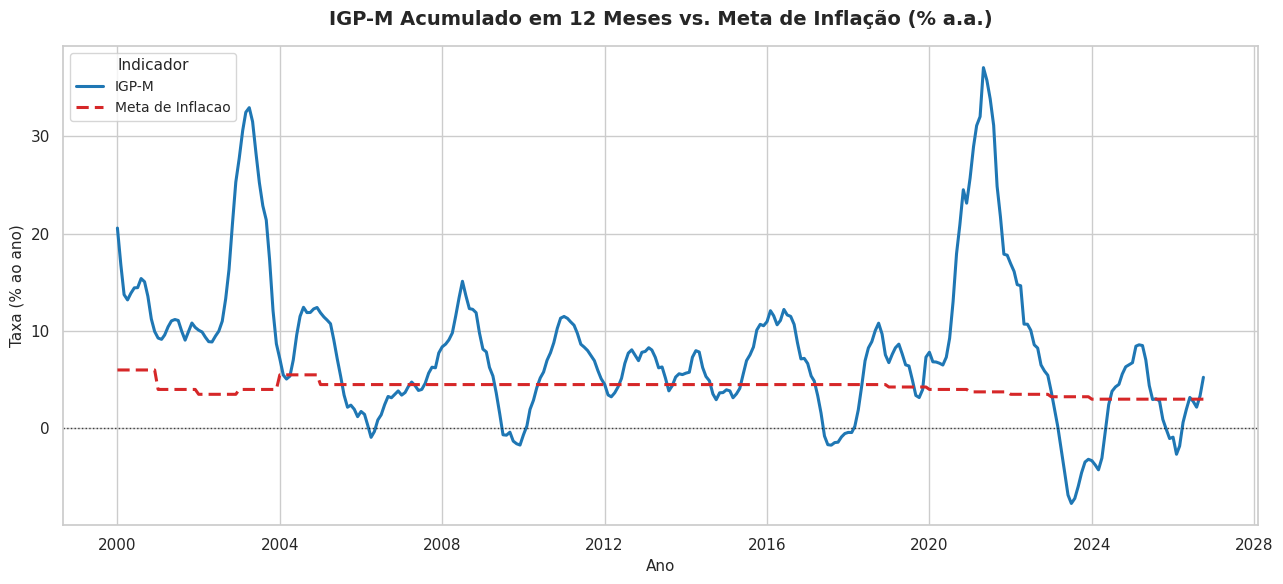

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtra a partir de 2000 para evitar a distorção da hiperinflação dos anos 1990 no eixo Y
df_plot = tabela_intermediaria_2[tabela_intermediaria_2['Date'] >= '2000-01-01'].copy()

# Configuração visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(13, 6))

# Plota as duas linhas (IGP-M acumulado em 12 meses vs. Meta de Inflação)
sns.lineplot(
    data=df_plot,
    x='Date',
    y='valor',
    hue='indicador',
    style='indicador',
    palette={'IGP-M': '#1f77b4', 'Meta de Inflacao': '#d62728'},
    dashes={'IGP-M': '', 'Meta de Inflacao': (4, 2)},
    linewidth=2.2
)

# Linha pontilhada no zero para destacar períodos de deflação
plt.axhline(0, color='black', linestyle=':', linewidth=1, alpha=0.7)

# Títulos e eixos
plt.title('IGP-M Acumulado em 12 Meses vs. Meta de Inflação (% a.a.)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ano', fontsize=11)
plt.ylabel('Taxa (% ao ano)', fontsize=11)
plt.legend(title='Indicador', fontsize=10, title_fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()